In [ ]:
# Cellule 1 : imports, graine, chemins
import os, glob, json, random, unicodedata
import numpy as np, pandas as pd
import torch
import matplotlib.pyplot as plt
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
dev = "cuda" if torch.cuda.is_available() else "cpu"
print("device :", dev)

hits = glob.glob("/kaggle/input/**/train.tsv", recursive=True)
assert hits, "train.tsv introuvable : ajoute ton dataset avec Add Input"
P = os.path.dirname(hits[0]) + "/"

def has_jpg(d):
    return os.path.isdir(d) and any(f.endswith(".jpg") for f in os.listdir(d)[:20])

IMG = next((d for d in (P + "images/images/", P + "images/") if has_jpg(d)), None)
assert IMG, "dossier d'images introuvable dans " + P

emb = glob.glob("/kaggle/input/**/emb/img_clip_vit_b32_train.npy", recursive=True)
assert emb, ("embeddings CLIP introuvables : Add Input, onglet Notebooks (ou Your Work), choisis la version v2 de "
             "ton notebook 02_embeddings_e2_e3 (sa sortie contient emb/img_clip_vit_b32_train.npy)")
EMB = os.path.dirname(emb[0]) + "/"
assert os.path.exists(EMB + "txt_train.npy"), "txt_train.npy manquant dans " + EMB

OUT = "/kaggle/working/"
for d in ("results/mlflow", "figures"):
    os.makedirs(OUT + d, exist_ok=True)
print("P   =", P)
print("IMG =", IMG)
print("EMB =", EMB)

device : cuda
P   = /kaggle/input/datasets/sahnounsahnoun/data-fakenewes/
IMG = /kaggle/input/datasets/sahnounsahnoun/data-fakenewes/images/images/
EMB = /kaggle/input/notebooks/sahnounsahnoun/e2-e3-embeddings/emb/


In [2]:
# Cellule 2 : splits, controle de version du dataset et d'alignement, embeddings propres
S = ["train", "val", "test"]
df = {s: pd.read_csv(P + s + ".tsv", sep="\t") for s in S}

ATTENDU = {"train": 7432, "val": 1403, "test": 1396}
for s in S:
    assert len(df[s]) == ATTENDU[s], (
        "%s : %d publications, %d attendues. Ce n'est pas la version nettoyee du dataset "
        "(l'ancienne version non nettoyee a 7792 / 1469 / 1450)." % (s, len(df[s]), ATTENDU[s]))

y = {s: df[s]["2_way_label"].values for s in S}
Xt = {s: np.load(EMB + "txt_%s.npy" % s) for s in S}                    # DistilBERT gele
Xi = {s: np.load(EMB + "img_clip_vit_b32_%s.npy" % s) for s in S}       # CLIP ViT-B/32 gele
for s in S:
    assert len(df[s]) == len(Xt[s]) == len(Xi[s]), (
        "%s : %d lignes dans le tsv, %d embeddings texte, %d embeddings image. "
        "Les embeddings viennent d'une autre version du dataset : relance 02." % (s, len(df[s]), len(Xt[s]), len(Xi[s])))
    print(s, len(df[s]), "exemples | texte", Xt[s].shape, "| image", Xi[s].shape)

have = {f[:-4] for f in os.listdir(IMG)}
assert df["test"]["id"].astype(str).isin(have).all(), "images du test manquantes : verifie la version du dataset"

train 7432 exemples | texte (7432, 768) | image (7432, 512)
val 1403 exemples | texte (1403, 768) | image (1403, 512)
test 1396 exemples | texte (1396, 768) | image (1396, 512)


In [3]:
# Cellule 3 : evaluation, entrainement (meme protocole que E2, E3d, E4b) et intervalle par bootstrap
GRID = [0.0003, 0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1]
GRID_ETENDUE = [0.00001, 0.00003, 0.0001, 0.0003, 0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1]

def metrics(y_true, p):
    pred = (p > 0.5).astype(int)
    return dict(acc=accuracy_score(y_true, pred),
                prec=precision_score(y_true, pred, average="macro", zero_division=0),
                rec=recall_score(y_true, pred, average="macro", zero_division=0),
                macro_f1=f1_score(y_true, pred, average="macro", zero_division=0),
                auc=roc_auc_score(y_true, p))

def entrainer(name, X, grid):
    """Regression logistique apres standardisation ; C choisi sur la validation uniquement."""
    mk = lambda C: make_pipeline(StandardScaler(), LogisticRegression(
        C=C, max_iter=3000, class_weight="balanced", random_state=SEED))
    val = {C: f1_score(y["val"], mk(C).fit(X["train"], y["train"]).predict(X["val"]), average="macro")
           for C in grid}
    best = max(val, key=val.get)
    if best in (grid[0], grid[-1]):
        print(name, ": attention, le meilleur C est en bord de grille")
    clf = mk(best).fit(X["train"], y["train"])
    pv = clf.predict_proba(X["val"])[:, 1]
    pt = clf.predict_proba(X["test"])[:, 1]
    m = metrics(y["test"], pt)
    print(name, "meilleur C =", best, "| val F1 =", round(val[best], 4),
          "| TEST propre", {k: round(float(v), 4) for k, v in m.items()})
    return dict(best_C=best, val_macro_f1=val[best], test=m), clf, pv

def f1_macro_lots(y_true, pred, idx):
    """Macro F1 binaire pour chaque reechantillon (lignes de idx), calculee a la main : rapide."""
    yb, pb = y_true[idx], pred[idx]
    out = []
    for c in (0, 1):
        tp = ((yb == c) & (pb == c)).sum(1)
        fp = ((yb != c) & (pb == c)).sum(1)
        fn = ((yb == c) & (pb != c)).sum(1)
        out.append(np.where(2 * tp + fp + fn > 0, 2 * tp / np.maximum(2 * tp + fp + fn, 1), 0.0))
    return (out[0] + out[1]) / 2

def ecart_points(y_true, p_a, p_b, B=1000):
    """Ecart de Macro F1 (a - b) en points, avec intervalle a 95 % par bootstrap sur le test."""
    rng = np.random.default_rng(SEED)
    pa, pb = (p_a > 0.5).astype(int), (p_b > 0.5).astype(int)
    g = 100 * (f1_score(y_true, pa, average="macro") - f1_score(y_true, pb, average="macro"))
    idx = rng.integers(0, len(y_true), size=(B, len(y_true)))
    d = 100 * (f1_macro_lots(y_true, pa, idx) - f1_macro_lots(y_true, pb, idx))
    return g, tuple(np.percentile(d, [2.5, 97.5]))

In [4]:
# Cellule 4 : les quatre modeles, entraines sur les donnees PROPRES (comme E2, E3d, E4b, E5b)
res, clf = {}, {}
res["E2"], clf["E2"], pv_txt = entrainer("E2 texte DistilBERT", Xt, GRID)
res["E3d"], clf["E3d"], pv_img = entrainer("E3d image CLIP", Xi, GRID_ETENDUE)
Xf = {s: np.hstack([Xt[s], Xi[s]]) for s in S}
res["E4b"], clf["E4b"], _ = entrainer("E4b fusion precoce", Xf, GRID_ETENDUE)

# E5b : moyenne ponderee des probabilites, poids du texte choisi sur la validation (donnees propres)
POIDS = [round(float(w), 1) for w in np.arange(0, 1.01, 0.1)]
val_f1 = {w: f1_score(y["val"], ((w * pv_txt + (1 - w) * pv_img) > 0.5).astype(int), average="macro") for w in POIDS}
w_best = max(val_f1, key=val_f1.get)
print("E5b fusion tardive : poids du texte w =", w_best, "| val F1 =", round(val_f1[w_best], 4))

def predire(xt, xi):
    """Probabilite 'vrai' des quatre modeles pour des embeddings texte (xt) et image (xi) donnes."""
    p2 = clf["E2"].predict_proba(xt)[:, 1]
    p3 = clf["E3d"].predict_proba(xi)[:, 1]
    p4 = clf["E4b"].predict_proba(np.hstack([xt, xi]))[:, 1]
    return {"E2": p2, "E3d": p3, "E4b": p4, "E5b": w_best * p2 + (1 - w_best) * p3}

propre = predire(Xt["test"], Xi["test"])
res["E5b"] = dict(poids_texte=w_best, val_macro_f1=val_f1[w_best], test=metrics(y["test"], propre["E5b"]))
print("E5b TEST propre", {k: round(float(v), 4) for k, v in res["E5b"]["test"].items()})

# controle : on doit retrouver tes chiffres (Macro F1 test propre : E2 = 0,801 ; E3d = 0,774 ; E4b, E5b : voir e4b/e5b_metrics.json)
for k, ref in (("E2", 0.801), ("E3d", 0.774)):
    ecart = res[k]["test"]["macro_f1"] - ref
    print("Controle %s : ecart avec la reference = %+.3f %s" % (k, ecart, "OK" if abs(ecart) <= 0.01 else
          "ATTENTION : verifie que les embeddings et le dataset sont ceux de 02 avant d'interpreter"))
plancher = metrics(y["test"], np.ones(len(y["test"])))["macro_f1"]
print("Plancher (tout vrai) : Macro F1 =", round(plancher, 3))

E2 texte DistilBERT meilleur C = 0.1 | val F1 = 0.8104 | TEST propre {'acc': 0.8009, 'prec': 0.8009, 'rec': 0.8008, 'macro_f1': 0.8008, 'auc': 0.8615}
E3d image CLIP meilleur C = 0.001 | val F1 = 0.7849 | TEST propre {'acc': 0.7744, 'prec': 0.7754, 'rec': 0.7742, 'macro_f1': 0.7741, 'auc': 0.8591}
E4b fusion precoce meilleur C = 0.001 | val F1 = 0.8502 | TEST propre {'acc': 0.8374, 'prec': 0.8383, 'rec': 0.8372, 'macro_f1': 0.8372, 'auc': 0.9074}
E5b fusion tardive : poids du texte w = 0.4 | val F1 = 0.8502
E5b TEST propre {'acc': 0.8431, 'prec': 0.8438, 'rec': 0.843, 'macro_f1': 0.843, 'auc': 0.9084}
Controle E2 : ecart avec la reference = -0.000 OK
Controle E3d : ecart avec la reference = +0.000 OK
Plancher (tout vrai) : Macro F1 = 0.335


In [5]:
# Cellule 5 : extracteurs (memes modeles et memes reglages que le notebook 02) et controle
from transformers import AutoTokenizer, AutoModel, CLIPVisionModelWithProjection

NUM_WORKERS = 2   # mets 0 si le calcul semble bloque
tok = AutoTokenizer.from_pretrained("distilbert-base-uncased")
bert = AutoModel.from_pretrained("distilbert-base-uncased").to(dev).eval()

def txt_emb(texts):
    """DistilBERT gele : moyenne des tokens (identique a la cellule 4 de 02)."""
    texts = list(texts)
    out = []
    for i in range(0, len(texts), 64):
        t = tok(texts[i:i + 64], padding=True, truncation=True, max_length=64, return_tensors="pt").to(dev)
        with torch.no_grad():
            h = bert(**t).last_hidden_state
        m = t["attention_mask"].unsqueeze(-1)
        out.append(((h * m).sum(1) / m.sum(1)).cpu().numpy())
    return np.concatenate(out).astype("float32")

CLIP_STATS = ([0.4815, 0.4578, 0.4082], [0.2686, 0.2613, 0.2758])

class ClipImg(torch.nn.Module):
    """Encodeur image de CLIP ViT-B/32 : vecteur de 512 nombres par image."""
    def __init__(self):
        super().__init__()
        self.m = CLIPVisionModelWithProjection.from_pretrained("openai/clip-vit-base-patch32")
    def forward(self, x):
        return self.m(pixel_values=x).image_embeds

clip = ClipImg().to(dev).eval()

class ImgsTf(Dataset):
    def __init__(self, ids, tfm):
        self.ids, self.tfm = list(ids), tfm
    def __len__(self):
        return len(self.ids)
    def __getitem__(self, i):
        return self.tfm(Image.open(IMG + self.ids[i] + ".jpg").convert("RGB"))

def transform_image(sigma=0):
    """Pretraitement de 02 ; avec sigma > 0, un flou gaussien est applique avant la conversion en tenseur."""
    ops = []
    if sigma > 0:
        k = 2 * int(np.ceil(3 * sigma)) + 1                      # taille du noyau, impaire
        ops.append(transforms.GaussianBlur(kernel_size=k, sigma=(float(sigma), float(sigma))))
    return transforms.Compose(ops + [transforms.ToTensor(), transforms.Normalize(*CLIP_STATS)])

def clip_emb(ids, sigma=0):
    out = []
    for b in DataLoader(ImgsTf(ids, transform_image(sigma)), batch_size=64, shuffle=False, num_workers=NUM_WORKERS):
        with torch.no_grad():
            out.append(clip(b.to(dev)).cpu().numpy())
    return np.concatenate(out).astype("float32")

# controle : recalculer les embeddings PROPRES de 128 publications de test doit redonner ceux de 02
n_ctl = 128
cos = lambda a, b: (a * b).sum(1) / (np.linalg.norm(a, axis=1) * np.linalg.norm(b, axis=1))
c_txt = cos(txt_emb(df["test"]["clean_title"].astype(str)[:n_ctl]), Xt["test"][:n_ctl]).min()
c_img = cos(clip_emb(df["test"]["id"].astype(str)[:n_ctl]), Xi["test"][:n_ctl]).min()
print("Controle des extracteurs (cosinus minimal avec les embeddings de 02) : texte %.5f | image %.5f" % (c_txt, c_img))
if min(c_txt, c_img) < 0.999:
    print("ATTENTION : les embeddings recalcules different de ceux de 02. Verifie que 02 (version v2) est bien "
          "en Input et que le dataset est le meme avant d'interpreter.")

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

... (6 outputs left out)

[transformers] CLIPVisionModelWithProjection LOAD REPORT from: openai/clip-vit-base-patch32
Key                                                          | Status     |  | 
-------------------------------------------------------------+------------+--+-
text_model.encoder.layers.{0...11}.self_attn.q_proj.weight   | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.k_proj.weight   | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm1.bias          | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.v_proj.bias     | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.mlp.fc2.bias              | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm2.bias          | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.out_proj.bias   | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.q_proj.bias     | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.mlp.fc1.weight            | UNEXPECTED |  | 
text_model.encoder.layers.{0

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

model.safetensors: downloading bytes:           |  0.00B            

Controle des extracteurs (cosinus minimal avec les embeddings de 02) : texte 1.00000 | image 1.00000


masque 30 % (part reelle des mots masques : 30.9 %) :
  avant : the ruthless efficiency of nazi germanys military
  apres : the ruthless efficiency of [MASK] germanys [MASK]
masque 50 % (part reelle des mots masques : 53.1 %) :
  avant : the ruthless efficiency of nazi germanys military
  apres : the ruthless [MASK] [MASK] [MASK] [MASK] military
embeddings degrades calcules : 6 versions de texte, 2 versions d'image


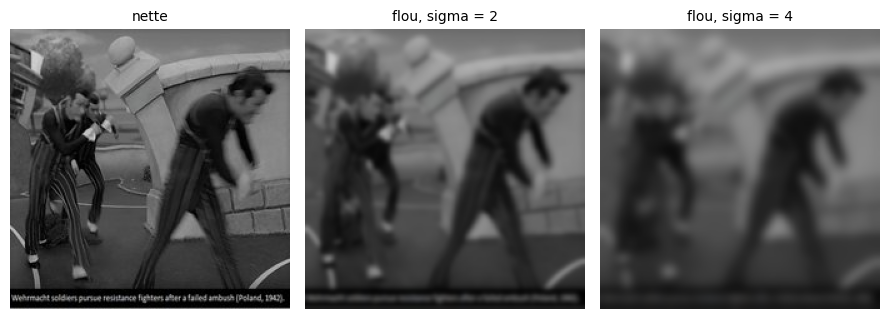

In [6]:
# Cellule 6 : degrader le test (texte masque, image floue) et recalculer les embeddings
NIVEAUX_TEXTE = [0.3, 0.5]     # part des mots masques
SIGMAS = [2, 4]                # intensite du flou
N_TIRAGES = 3                  # nombre de tirages du masque (graines differentes)

def masquer(titres, p, rng):
    """Remplace par [MASK] une part p des mots de chaque titre, choisis au hasard."""
    sortie, n_mots, n_mask = [], 0, 0
    for t in titres:
        mots = str(t).split()
        k = int(np.floor(p * len(mots) + 0.5))
        if k > 0:
            for i in rng.choice(len(mots), size=k, replace=False):
                mots[i] = "[MASK]"
        n_mots += len(mots); n_mask += k
        sortie.append(" ".join(mots))
    return sortie, n_mask / max(n_mots, 1)

titres = df["test"]["clean_title"].astype(str).tolist()
Xt_deg = {}
for p in NIVEAUX_TEXTE:
    for d in range(N_TIRAGES):
        masques, part = masquer(titres, p, np.random.default_rng([SEED, int(round(p * 100)), d]))
        Xt_deg[(p, d)] = txt_emb(masques)
        if d == 0:
            print("masque %d %% (part reelle des mots masques : %.1f %%) :" % (100 * p, 100 * part))
            print("  avant :", titres[0]); print("  apres :", masques[0])

ids_test = df["test"]["id"].astype(str)
Xi_deg = {sg: clip_emb(ids_test, sg) for sg in SIGMAS}
print("embeddings degrades calcules :", len(Xt_deg), "versions de texte,", len(Xi_deg), "versions d'image")

# exemple visuel du flou pour les diapos
im = Image.open(IMG + ids_test.iloc[0] + ".jpg").convert("RGB")
fig, ax = plt.subplots(1, 3, figsize=(9, 3.3))
for a, (lib, sg) in zip(ax, [("nette", 0)] + [("flou, sigma = %d" % s_, s_) for s_ in SIGMAS]):
    a.imshow(transforms.GaussianBlur(2 * int(np.ceil(3 * sg)) + 1, (float(sg), float(sg)))(im) if sg else im)
    a.set_title(lib, fontsize=10); a.axis("off")
plt.tight_layout()
plt.savefig(OUT + "figures/rq3_exemple_flou.png", dpi=150, bbox_inches="tight")
plt.show()

In [7]:
# Cellule 7 : les quatre modeles sur chaque scenario (Macro F1 moyenne et ecart-type sur les tirages du masque)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 20)
SCENARIOS = [("propre", 0, 0), ("texte30", 0.3, 0), ("texte50", 0.5, 0),
             ("flou2", 0, 2), ("flou4", 0, 4), ("texte50_flou4", 0.5, 4)]
MODELES = ["E2", "E3d", "E4b", "E5b"]
LIB = {"E2": "E2 texte (DistilBERT)", "E3d": "E3d image (CLIP)", "E4b": "E4b fusion precoce", "E5b": "E5b fusion tardive"}

mesures, proba0 = {}, {}          # (modele, scenario) -> mesures par tirage ; probabilites du premier tirage
for nom, p, sg in SCENARIOS:
    for d in (range(N_TIRAGES) if p > 0 else [0]):
        xt = Xt_deg[(p, d)] if p > 0 else Xt["test"]
        xi = Xi_deg[sg] if sg > 0 else Xi["test"]
        pr = predire(xt, xi)
        for m in MODELES:
            mesures.setdefault((m, nom), []).append(metrics(y["test"], pr[m]))
            if d == 0:
                proba0[(m, nom)] = pr[m]

def agreger(cle):
    moy = pd.DataFrame({sc: {m: np.mean([x[cle] for x in mesures[(m, sc)]]) for m in MODELES} for sc, _, _ in SCENARIOS})
    sd = pd.DataFrame({sc: {m: np.std([x[cle] for x in mesures[(m, sc)]]) for m in MODELES} for sc, _, _ in SCENARIOS})
    return moy, sd

f1_moy, f1_sd = agreger("macro_f1")
acc_moy, _ = agreger("acc")
auc_moy, _ = agreger("auc")
f1_moy.index = f1_sd.index = [LIB[m] for m in MODELES]

print("Macro F1 sur le test (moyenne des %d tirages du masque ; plancher tout vrai = %.3f) :" % (N_TIRAGES, plancher))
print(f1_moy.round(3), "\n")
print("Ecart-type de la Macro F1 entre les tirages du masque (0 = pas de hasard dans le scenario) :")
print(f1_sd.round(3), "\n")
variation = ((f1_moy.sub(f1_moy["propre"], axis=0)) * 100).round(1).drop(columns="propre")
print("Variation par rapport au test propre (points de Macro F1) :")
print(variation)

Macro F1 sur le test (moyenne des 3 tirages du masque ; plancher tout vrai = 0.335) :
                       propre  texte30  texte50  flou2  flou4  texte50_flou4
E2 texte (DistilBERT)   0.801    0.703    0.614  0.801  0.801          0.614
E3d image (CLIP)        0.774    0.774    0.774  0.698  0.623          0.623
E4b fusion precoce      0.837    0.819    0.805  0.809  0.784          0.696
E5b fusion tardive      0.843    0.798    0.776  0.824  0.792          0.656 

Ecart-type de la Macro F1 entre les tirages du masque (0 = pas de hasard dans le scenario) :
                       propre  texte30  texte50  flou2  flou4  texte50_flou4
E2 texte (DistilBERT)     0.0    0.006    0.004    0.0    0.0          0.004
E3d image (CLIP)          0.0    0.000    0.000    0.0    0.0          0.000
E4b fusion precoce        0.0    0.004    0.004    0.0    0.0          0.005
E5b fusion tardive        0.0    0.001    0.005    0.0    0.0          0.009 

Variation par rapport au test propre (points de

In [8]:
# Cellule 8 : la fusion fait-elle mieux que chaque modalite seule dans chaque scenario degrade ?
lignes, verdicts, ecarts = {}, {}, {}
for nom, p, sg in SCENARIOS:
    ligne = {}
    for fus in ("E4b", "E5b"):
        v = []
        for ref in ("E2", "E3d"):
            g, (lo, hi) = ecart_points(y["test"], proba0[(fus, nom)], proba0[(ref, nom)])
            ligne["%s - %s" % (fus, ref)] = "%+.1f [%+.1f ; %+.1f]" % (g, lo, hi)
            ecarts["%s_%s_vs_%s" % (fus, nom, ref)] = (g, lo, hi)
            v.append((lo, hi))
        if all(lo > 0 for lo, _ in v):
            verdicts[(fus, nom)] = "mieux que les deux modalites seules"
        elif any(hi < 0 for _, hi in v):
            verdicts[(fus, nom)] = "moins bonne qu'une des deux modalites"
        else:
            verdicts[(fus, nom)] = "ecart non etabli face a au moins une modalite"
    lignes[nom] = ligne
tab_ecarts = pd.DataFrame(lignes).T
print("Ecart de Macro F1 de la fusion face a chaque modalite seule, en points [intervalle a 95 %] (premier tirage) :")
print(tab_ecarts, "\n")
for (fus, nom), v in verdicts.items():
    print("%-4s | %-14s | %s" % (fus, nom, v))
print("\nRappel : une seule graine d'entrainement ; un intervalle qui contient 0 n'est pas une difference etablie.")

Ecart de Macro F1 de la fusion face a chaque modalite seule, en points [intervalle a 95 %] (premier tirage) :
                            E4b - E2              E4b - E3d               E5b - E2              E5b - E3d
propre            +3.6 [+1.9 ; +5.4]     +6.3 [+4.1 ; +8.7]     +4.2 [+2.4 ; +6.0]     +6.9 [+4.9 ; +9.1]
texte30         +10.6 [+8.1 ; +13.0]     +4.1 [+1.9 ; +6.3]    +8.7 [+6.4 ; +11.0]     +2.3 [+0.1 ; +4.4]
texte50        +19.7 [+17.0 ; +22.3]     +3.4 [+1.2 ; +5.7]  +16.7 [+14.2 ; +19.1]     +0.4 [-1.7 ; +2.8]
flou2             +0.8 [-1.1 ; +2.6]   +11.1 [+8.6 ; +13.9]     +2.3 [+0.7 ; +3.9]  +12.6 [+10.3 ; +15.2]
flou4             -1.7 [-3.7 ; +0.1]  +16.0 [+13.3 ; +19.1]     -0.9 [-2.5 ; +0.8]  +16.9 [+14.3 ; +19.7]
texte50_flou4    +7.9 [+5.4 ; +10.4]     +6.7 [+4.0 ; +9.6]     +3.3 [+1.1 ; +5.5]     +2.1 [-0.7 ; +4.9] 

E4b  | propre         | mieux que les deux modalites seules
E5b  | propre         | mieux que les deux modalites seules
E4b  | texte30        | mi

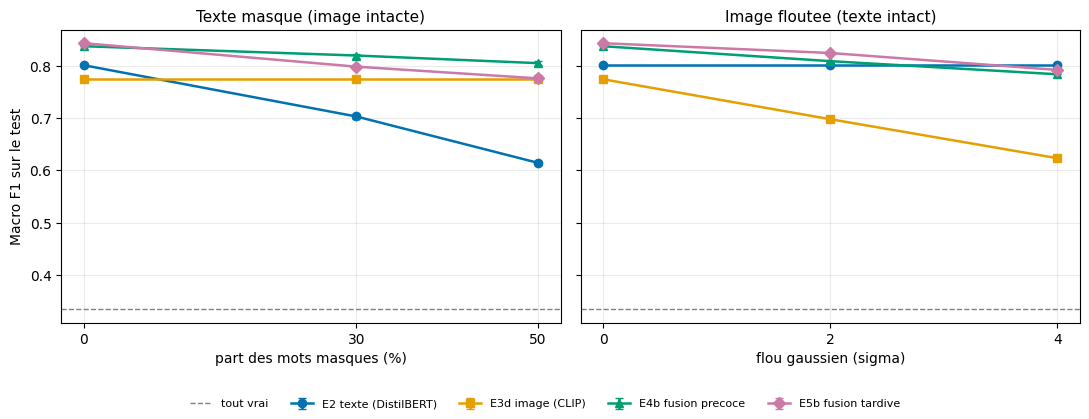

In [9]:
# Cellule 9 : figure de synthese
COULEURS = {"E2": "#0072B2", "E3d": "#E69F00", "E4b": "#009E73", "E5b": "#CC79A7"}
MARQ = {"E2": "o", "E3d": "s", "E4b": "^", "E5b": "D"}
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)

def courbe(a, xs, noms, etiquettes, titre, xlabel):
    for m in MODELES:
        moy = [f1_moy.loc[LIB[m], sc] for sc in noms]
        sd = [f1_sd.loc[LIB[m], sc] for sc in noms]
        a.errorbar(xs, moy, yerr=sd, color=COULEURS[m], marker=MARQ[m], lw=1.8, ms=6, capsize=3, label=LIB[m])
    a.axhline(plancher, color="grey", ls="--", lw=1, label="tout vrai")
    a.set_xticks(xs); a.set_xticklabels(etiquettes)
    a.set_title(titre, fontsize=11); a.set_xlabel(xlabel); a.grid(alpha=0.25)

courbe(ax[0], [0, 30, 50], ["propre", "texte30", "texte50"], ["0", "30", "50"],
       "Texte masque (image intacte)", "part des mots masques (%)")
courbe(ax[1], [0, 2, 4], ["propre", "flou2", "flou4"], ["0", "2", "4"],
       "Image floutee (texte intact)", "flou gaussien (sigma)")
ax[0].set_ylabel("Macro F1 sur le test")
h, l = ax[0].get_legend_handles_labels()
fig.legend(h, l, loc="lower center", ncol=5, fontsize=8, frameon=False)
plt.tight_layout(rect=[0, 0.08, 1, 1])
plt.savefig(OUT + "figures/rq3_robustesse.png", dpi=150, bbox_inches="tight")
plt.show()

In [10]:
# Cellule 10 : fichiers de resultats (metriques completes et JSON pour MLflow)
def slug(t):
    return "_".join(unicodedata.normalize("NFKD", t).encode("ascii", "ignore").decode().lower().split())

met = {}
for m in MODELES:
    for nom, _, _ in SCENARIOS:
        met["f1_%s_%s" % (m, nom)] = float(f1_moy.loc[LIB[m], nom])
        met["acc_%s_%s" % (m, nom)] = float(acc_moy.loc[m, nom])
        if nom != "propre":
            met["chute_f1_pts_%s_%s" % (m, nom)] = float(100 * (f1_moy.loc[LIB[m], nom] - f1_moy.loc[LIB[m], "propre"]))
for cle, (g, lo, hi) in ecarts.items():
    met["ecart_f1_pts_" + cle] = float(g)

params = dict(entree="titre + image", modeles="E2 DistilBERT, E3d CLIP, E4b fusion precoce, E5b fusion tardive (entraines sur donnees propres)",
              degradation_test="mots remplaces par [MASK] (30 %, 50 %), flou gaussien (sigma 2, 4)",
              tirages_masque=N_TIRAGES, poids_texte_E5b=w_best, graine=SEED, n_test=len(y["test"]))
out = dict(etape="RQ3", nom="robustesse_modalite", params=params, metrics=met,
           tags=dict(source="notebook Kaggle 07_rq3_robustesse"))
with open(OUT + "results/mlflow/resultat_RQ3_robustesse_modalite.json", "w", encoding="utf-8") as f:
    json.dump(out, f, indent=2, ensure_ascii=False)

log = dict(seed=SEED, n_tirages=N_TIRAGES, niveaux_texte=NIVEAUX_TEXTE, sigmas=SIGMAS, plancher_f1=plancher,
           modeles_propres=res, f1_moyenne=f1_moy.to_dict(), f1_ecart_type=f1_sd.to_dict(),
           accuracy_moyenne=acc_moy.to_dict(), auc_moyenne=auc_moy.to_dict(),
           variation_points=variation.to_dict(), ecarts_fusion_points={k: list(v) for k, v in ecarts.items()},
           verdicts={"%s|%s" % k: v for k, v in verdicts.items()})
with open(OUT + "results/rq3_metrics.json", "w", encoding="utf-8") as f:
    json.dump(log, f, indent=2, ensure_ascii=False, default=lambda o: o.item() if hasattr(o, "item") else str(o))

for root, _, files in os.walk(OUT):
    for fn in sorted(files):
        p = os.path.join(root, fn)
        print(p, round(os.path.getsize(p) / 1e6, 2), "Mo")

/kaggle/working/__notebook__.ipynb 0.32 Mo
/kaggle/working/figures/rq3_exemple_flou.png 0.27 Mo
/kaggle/working/figures/rq3_robustesse.png 0.08 Mo
/kaggle/working/results/rq3_metrics.json 0.01 Mo
/kaggle/working/results/mlflow/resultat_RQ3_robustesse_modalite.json 0.0 Mo
